# 02 - Exploratory Data Analysis (EDA)
**Project:** Credit Approval Readiness — predicting credit card approval odds

**Goal of this notebook:** understand which features actually relate to approval outcome before modeling.
This is where the "insight for new credit builders" angle takes shape — the charts and observations here
feed directly into the README's Key Findings section.

Loads the cleaned dataset produced by `01_data_cleaning.ipynb`.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)

## 1. Load the cleaned data

In [8]:
df = pd.read_csv('../data/processed/cc_approvals_clean.csv')

print(f"Shape: {df.shape}")
df.head()

Shape: (690, 16)


,gender,age,debt,married,bank_customer,education_level,ethnicity,years_employed,prior_default,employed,credit_score,drivers_license,citizen,zip_code,income,approved
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,202,0,1
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,43,560,1
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,280,824,1
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,100,3,1
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,120,0,1


## 2. Target variable recap

Quick refresher on the approval split before digging into individual features.

In [9]:
target_col = 'approved'

approval_counts = df[target_col].value_counts()
approval_pct = df[target_col].value_counts(normalize=True) * 100

print(approval_counts)
print()
print(approval_pct.round(1))

approved
0    383
1    307
Name: count, dtype: int64

approved
0    55.5
1    44.5
Name: proportion, dtype: float64


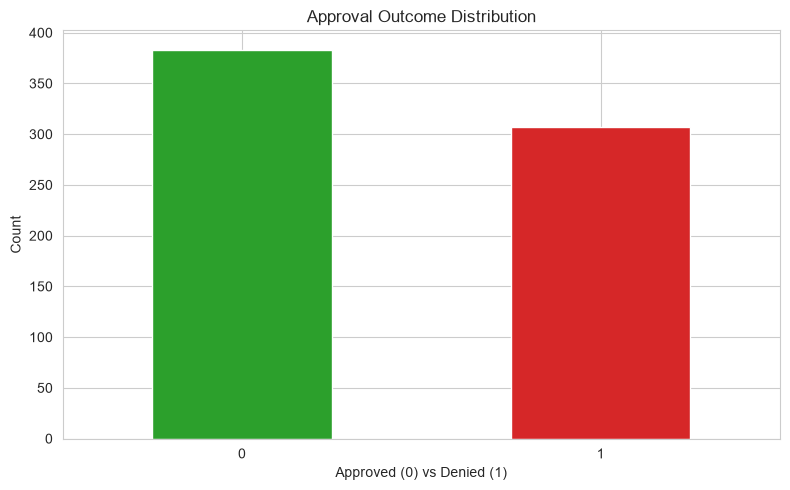

In [22]:
fig, ax = plt.subplots()
approval_counts.plot(kind='bar', ax=ax, color=['#2ca02c', '#d62728'])
ax.set_title('Approval Outcome Distribution')
ax.set_xlabel('Approved (0) vs Denied (1)')
ax.set_ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../reports/figures/target_distribution.png', dpi=150)
plt.show()

## 3. Numeric features vs. approval

For each numeric column, compare the distribution between approved and denied applicants.
Look for separation between the two groups — a feature where approved/denied look nearly identical
probably isn't very predictive; one where they clearly diverge likely is.

In [23]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if target_col in numeric_cols:
    numeric_cols.remove(target_col)

numeric_cols

['age', 'debt', 'years_employed', 'credit_score', 'zip_code', 'income']

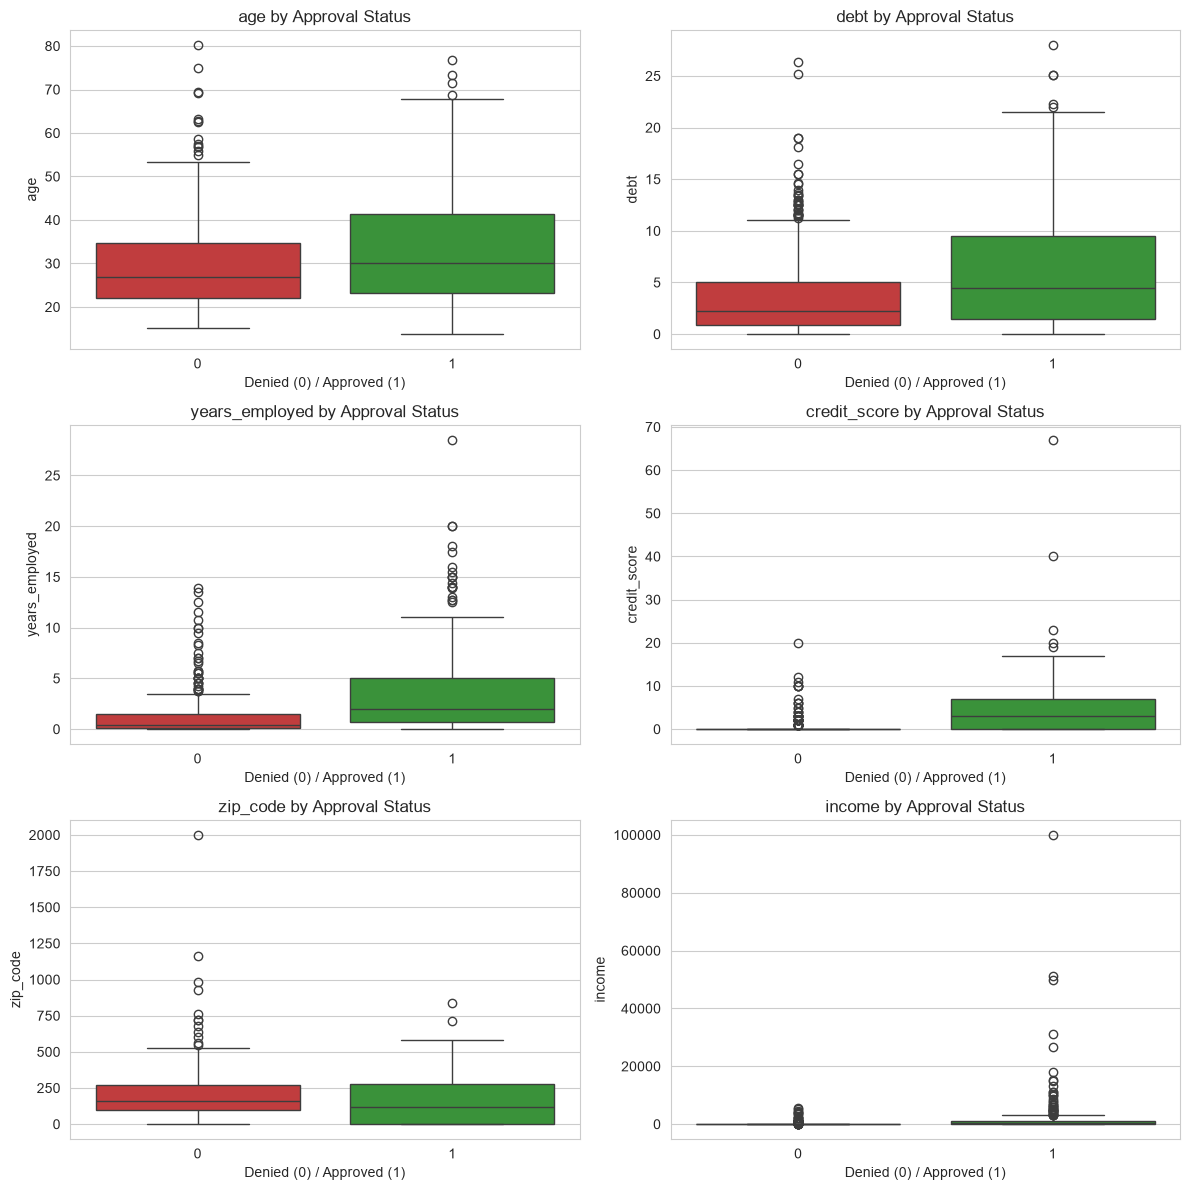

In [24]:
fig, axes = plt.subplots(nrows=(len(numeric_cols) + 1) // 2, ncols=2, figsize=(12, 4 * ((len(numeric_cols) + 1) // 2)))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x=target_col, y=col, ax=axes[i], hue=target_col, palette=['#d62728', '#2ca02c'], legend=False)
    axes[i].set_title(f'{col} by Approval Status')
    axes[i].set_xlabel('Denied (0) / Approved (1)')

# Hide any unused subplot
for j in range(len(numeric_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('../reports/figures/numeric_features_by_approval.png', dpi=150)
plt.show()

In [27]:
#Note: Checking to see if income was also scaled for the purpose of anonymity in this dataset.
# Seems that it was; will update readme 
#df['income'].describe()

## 4. Correlation with approval

A quick numeric summary of how strongly each numeric feature correlates with approval outcome.
This isn't the final word on feature importance, but it's a fast first signal.

In [28]:
correlations = df[numeric_cols + [target_col]].corr()[target_col].drop(target_col).sort_values(key=abs, ascending=False)
correlations

credit_score      0.406410
years_employed    0.322475
debt              0.206294
income            0.175657
age               0.168134
zip_code         -0.099598
Name: approved, dtype: float64

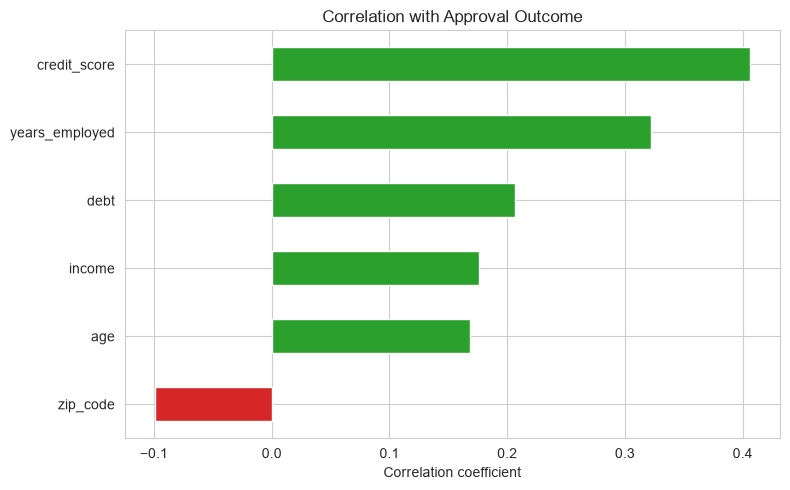

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
correlations.plot(kind='barh', ax=ax, color=['#2ca02c' if v > 0 else '#d62728' for v in correlations])
ax.set_title('Correlation with Approval Outcome')
ax.set_xlabel('Correlation coefficient')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/figures/correlation_with_approval.png', dpi=150)
plt.show()

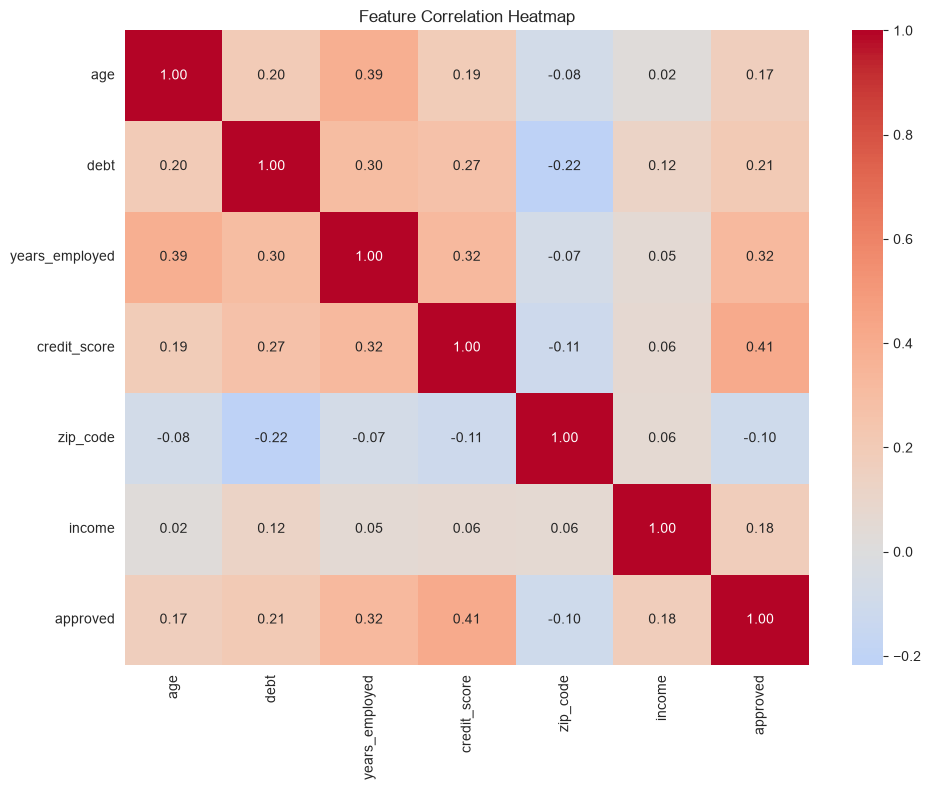

In [29]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[numeric_cols + [target_col]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=150)
plt.show()

## 5. Categorical features vs. approval

For each categorical column, look at approval rate broken down by category. This is where you'll find
findings like "applicants with X status get approved at a much higher/lower rate" — useful,
concrete takeaways for the README.

In [30]:
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
categorical_cols

/var/folders/cn/7pxxg23s6p1_p4j6jxwqd_rw0000gn/T/ipykernel_63707/611271536.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


['gender',
 'married',
 'bank_customer',
 'education_level',
 'ethnicity',
 'prior_default',
 'employed',
 'drivers_license',
 'citizen']

In [31]:
for col in categorical_cols:
    approval_rate = df.groupby(col)[target_col].mean().sort_values(ascending=False)
    print(f"\nApproval rate by {col}:")
    print((approval_rate * 100).round(1))


Approval rate by gender:
gender
a    46.7
b    43.5
Name: approved, dtype: float64

Approval rate by married:
married
l    100.0
u     49.5
y     27.6
Name: approved, dtype: float64

Approval rate by bank_customer:
bank_customer
gg    100.0
g      49.5
p      27.6
Name: approved, dtype: float64

Approval rate by education_level:
education_level
x     84.2
cc    70.7
r     66.7
q     65.4
e     56.0
w     51.6
c     45.2
m     42.1
aa    35.2
j     30.0
k     27.5
i     23.7
d     23.3
ff    13.2
Name: approved, dtype: float64

Approval rate by ethnicity:
ethnicity
z     75.0
h     63.0
n     50.0
o     50.0
v     42.4
bb    42.4
j     37.5
dd    33.3
ff    14.0
Name: approved, dtype: float64

Approval rate by prior_default:
prior_default
t    78.7
f     7.0
Name: approved, dtype: float64

Approval rate by employed:
employed
t    70.8
f    24.8
Name: approved, dtype: float64

Approval rate by drivers_license:
drivers_license
t    46.2
f    43.0
Name: approved, dtype: float64

Approval 

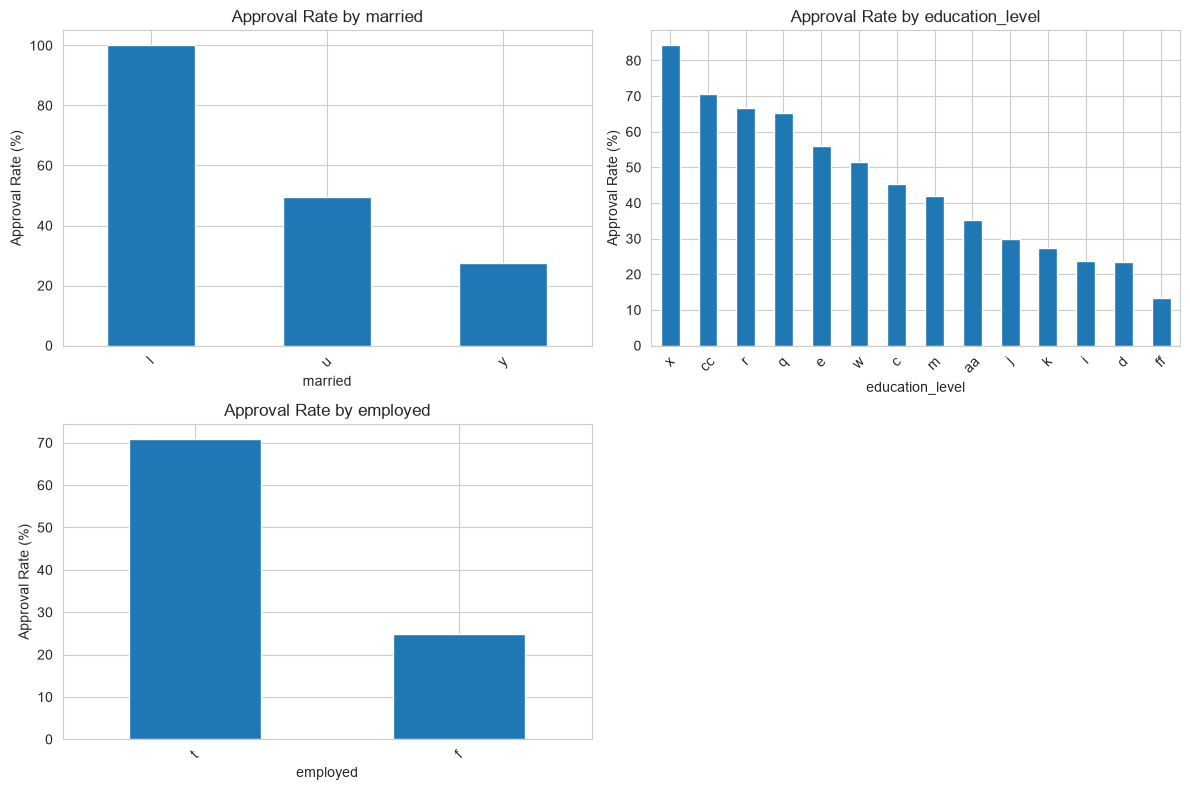

In [46]:
# Visualize the categorical column(s) that look most interesting from the printout above.
cols_to_plot = [categorical_cols[1], categorical_cols[3], categorical_cols[6]]

fig, axes = plt.subplots(nrows=(len(cols_to_plot) + 1) // 2, ncols=2, figsize=(12, 4 * ((len(cols_to_plot) + 1) // 2)))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    approval_rate = df.groupby(col)[target_col].mean().sort_values(ascending=False) * 100
    approval_rate.plot(kind='bar', ax=axes[i], color='#1f77b4')
    axes[i].set_title(f'Approval Rate by {col}')
    axes[i].set_ylabel('Approval Rate (%)')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(cols_to_plot), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('../reports/figures/categorical_approval_rates.png', dpi=150)
plt.show()

## 6. Feature relationships worth flagging for modeling

Quick check for multicollinearity (features that are highly correlated *with each other*, not just
the target) — this matters more for logistic regression's interpretability than for tree-based models,
but worth knowing either way.

In [21]:
corr_matrix = df[numeric_cols].corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = [
    (col, row, upper_triangle.loc[row, col])
    for col in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, col]) and upper_triangle.loc[row, col] > 0.6
]

if high_corr_pairs:
    print("Highly correlated feature pairs (>0.6):")
    for col, row, val in high_corr_pairs:
        print(f"  {row} <-> {col}: {val:.2f}")
else:
    print("No feature pairs with correlation above 0.6 — no major multicollinearity concerns.")

No feature pairs with correlation above 0.6 — no major multicollinearity concerns.


## Summary

- Strongest positive predictor(s) of approval: Credit Score(0.41), Years Employed (0.32) show 
the clearest positive relationship with approval.
- Strongest negative predictor(s) of approval: Zip Code shows a negative correlation with approval,
but at a -0.10 it's quite weak and may reflect minor regional patterns in the original data rather than a meaningful driver of approval.  
- Most interesting categorical finding: Age was not as strong of a signal as I 
previously hypothesized prior to this data. While it may still tie in negatively
as younger have also been employed less time, another strong predictor of approval
status
- Multicollinearity concerns (if any): No major multicollinearity concers, as no 
feauture pairs with correlation at or above .6. 
- Anything surprising or counter-intuitive: The debt being a moderate indicator of approval
was suprising, orignially expected to be a higher determinant of a bank's willingness to
authorize a bigger line of credit. 
